# 79. Word Search
**Difficulty:** 🟡 Medium · **Topic:** Backtracking · **Pattern:** [Grid Backtracking](README.md) · **LeetCode:** https://leetcode.com/problems/word-search/

## 💡 Concepts

**Core concept(s):** **Backtracking DFS** across the grid, matching the word letter by letter.

**Why it applies here:** A word is a path of adjacent cells. From every cell that matches the first letter, DFS to neighbors matching the next letter, marking cells used so a path can't reuse one; undo the mark when you back out.

**Key intuition:** Follow the word cell to cell; mark a cell used while exploring, then restore it.

---

### 📚 Working with a Matrix (Grid)
A matrix is a list of rows. Common moves: walk with `(r, c)` coordinates, **transpose** (swap rows/columns), or use the first row/column as scratch space to save memory.

### 📚 What is DFS (depth-first search)?
- **What it is:** a way to explore choices by going as deep as possible down one route before trying the next one.
- **Mental picture:** walking a maze with one hand on the wall; at a dead end you walk back to the last junction and take the next turn.
- **How it is coded:** recursion. Each call handles one cell; the call stack remembers the route so far, so returning from a call *is* walking back.
- **Cost:** each call does O(1) work plus its recursive calls; the stack depth equals the route length (here at most `L`, the word length).

### 📚 What is Backtracking?
**Backtracking** tries a step, explores, then **undoes** it. On a grid: mark a cell used, search neighbors, then restore it.
- **Why restore:** a cell that failed on one route may be exactly what another route needs. Undoing the mark on the way back keeps the board clean for the next try.
- **Pruning:** stop a route the moment it cannot succeed (here: the next letter doesn't match). That is what keeps backtracking far below "try every path".

---

**Prerequisite knowledge:**
- Grid DFS.
- Backtracking (mark / restore).

## 📝 Problem

Does the word exist in the grid as a path of adjacent (up/down/left/right) cells, no cell reused?

**Example**
```
board=[["A","B","C","E"],["S","F","C","S"],["A","D","E","E"]], word="ABCCED" -> True
```

**Constraints:** `1 ≤ rows, cols ≤ 6`, `1 ≤ len(word) ≤ 15`, letters are upper/lower-case English.

> Two approaches: **brute force** (build every path of `len(word)` cells, compare its letters at the end) → **backtracking DFS** (grow one path letter by letter, stop at the first wrong letter, mark and restore cells).

In [1]:
from typing import List

# The LeetCode example board; tests copy it so no approach can leak changes into another.
EXAMPLE_BOARD = [["A","B","C","E"],["S","F","C","S"],["A","D","E","E"]]

### Approach 1 — Brute force: enumerate every path, compare at the end

**Idea:** From every start cell, build **every** self-avoiding path of exactly `L = len(word)` adjacent cells (a list of coordinates, so no cell repeats). Only when a path is complete, read its letters and compare them with `word`. Letters never steer the search, so a path that went wrong at its 2nd letter is still grown to full length.

**Time:** `O(rows·cols·3^L·L)`: up to `4·3^(L-1)` paths per start cell (after the first step, one neighbour is the cell you came from), and each path costs `O(L)` to copy, check membership and join. **Space:** `O(L)` for the current path and the recursion.

In [2]:
def exist_brute(board: List[List[str]], word: str) -> bool:
    rows, cols, L = len(board), len(board[0]), len(word)

    def paths_from(r, c, path):           # yield every self-avoiding path that extends `path` to L cells
        if len(path) == L:
            yield path
            return
        for dr, dc in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < rows and 0 <= nc < cols and (nr, nc) not in path:   # on the board, not reused
                yield from paths_from(nr, nc, path + [(nr, nc)])             # letters are ignored here

    for r in range(rows):
        for c in range(cols):
            for path in paths_from(r, c, [(r, c)]):
                if "".join(board[i][j] for i, j in path) == word:            # compare only at the end
                    return True
    return False

### Approach 2 — Backtracking DFS (prune + mark and restore)

**Idea:** Try each starting cell. DFS matches `word[i]`, marks the cell used, recurses on four neighbors for `word[i+1]`, then restores the cell.

This is the **grid backtracking template**: check the cell → choose (mark it `#`) → explore the 4 neighbours → un-choose (restore the letter).

**Time:** `O(rows·cols·3^L)` worst case: at most `4·3^(L-1)` calls per start cell, `O(1)` each. On real boards the letter check prunes most routes after a step or two. **Space:** `O(L)` recursion; the mark lives in the board itself, so no `visited` set is needed.

In [3]:
def exist(board, word):
    rows, cols = len(board), len(board[0])
    def dfs(r, c, i):                      # can we match word[i:] starting at cell (r, c)?
        if i == len(word):
            return True                    # matched every letter
        if r < 0 or c < 0 or r >= rows or c >= cols or board[r][c] != word[i]:
            return False                   # off the board, or the letter doesn't match
        tmp = board[r][c]; board[r][c] = "#"   # mark this cell used (can't reuse within a word)
        found = (dfs(r+1,c,i+1) or dfs(r-1,c,i+1) or
                 dfs(r,c+1,i+1) or dfs(r,c-1,i+1))   # try all 4 neighbors for the next letter
        board[r][c] = tmp                  # restore the cell (backtrack)
        return found
    return any(dfs(r, c, 0) for r in range(rows) for c in range(cols))   # try every start cell

In [4]:
# Correctness check
tests = [
    (EXAMPLE_BOARD, "ABCCED", True),
    (EXAMPLE_BOARD, "SEE", True),
    (EXAMPLE_BOARD, "ABCB", False),                     # the 2nd B would need the used B cell again
    ([["A"]], "A", True),                               # single cell
    ([["a", "a"]], "aaa", False),                       # only 2 cells: a 3-letter path must reuse one
    ([["C","A","A"],["A","A","A"],["B","C","D"]], "AAB", True),   # needs a cell freed after a failed route
    ([["A","B","C","E"],["S","F","E","S"],["A","D","E","E"]], "ABCESEEEFS", True),
]
for fn in (exist_brute, exist):
    for board, word, exp in tests:
        b = [row[:] for row in board]
        got = fn(b, word)
        assert got == exp, f"{fn.__name__}({word!r}) = {got}, expected {exp}"
        assert b == board, f"{fn.__name__} left the board modified"   # every mark was restored
    print(f"{fn.__name__:12} passed {len(tests)} tests")
print("\nAll tests passed")

exist_brute  passed 7 tests
exist        passed 7 tests

All tests passed


## ⏱️ Empirically Checking the Complexities

We time each approach on inputs of growing size and read the **ratio** between consecutive runs. Word Search has two size knobs, so we turn them one at a time.

| Sweep | What grows | Board | Expected ratio per step |
|---|---|---|---|
| 1 | grid side `n` doubles (cells ×4), word `"AAAB"` | all `'A'` | ≈ **4×** for both: linear in the number of cells |
| 2 | word length `L` grows by 1 | 6×6 all `'A'`, word `"A…AB"` | ≈ **2–3×** for both: exponential in `L` (below 3× because walls and used cells cut branches) |
| 3 | word length `L` grows by 1 | 6×6 random letters, word `"A…AB"` | brute ≈ **2–3×**, backtracking ≈ **1×** (pruning) |

Sweeps 1 and 2 are the **worst case**: every letter matches except the missing final `'B'`, so no route can stop early and both approaches explore the same paths; backtracking is only a constant factor faster (no path copies, no string building). Sweep 3 is a **typical** board: there the letter check cuts almost every route at once, which is the whole point of pruning.

`exist` marks cells in place but restores every one before returning (the correctness check asserts this), so reusing a board across calls is safe; each call still gets a fresh board from the generator.

Sweep 1 - n = grid side (doubling)

brute force (all paths)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       1.67 |           n/a
       20 |       7.97 |         4.77x
       40 |      32.95 |         4.14x
       80 |     134.69 |         4.09x

backtracking DFS
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
       10 |       0.53 |           n/a
       20 |       2.18 |         4.10x
       40 |       9.36 |         4.29x


       80 |      38.95 |         4.16x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


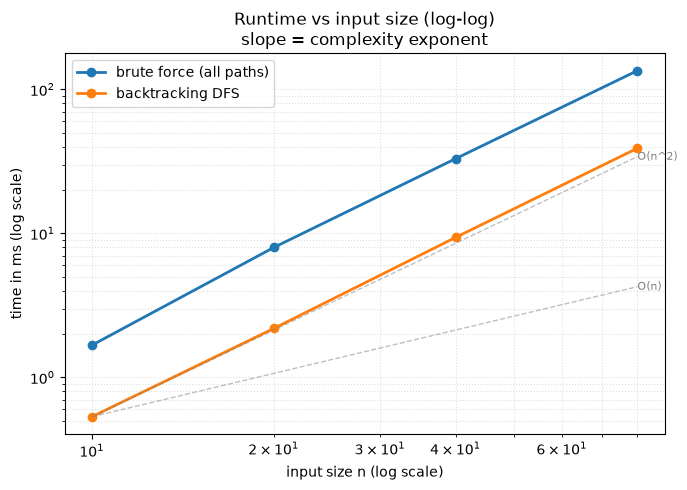


Sweep 2 - n = word length L, all-'A' board (worst case)

brute force (all paths)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        6 |       3.33 |           n/a
        7 |       8.43 |         2.53x
        8 |      19.83 |         2.35x
        9 |      44.58 |         2.25x
       10 |     102.78 |         2.31x

backtracking DFS
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        6 |       1.17 |           n/a
        7 |       2.56 |         2.18x
        8 |       6.00 |         2.34x
        9 |      13.17 |         2.20x
       10 |      28.14 |         2.14x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.

Sweep 3 - n = word length L, random board (pruning at work)

brute force (all paths)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        6 |       3.58 |           n/a
        7 |       8.92 |         2.49x


        8 |      21.07 |         2.36x
        9 |      47.98 |         2.28x


       10 |     108.56 |         2.26x

backtracking DFS
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
        6 |       0.00 |           n/a
        7 |       0.00 |         1.11x
        8 |       0.00 |         0.84x
        9 |       0.00 |         1.14x
       10 |       0.00 |         1.01x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


In [5]:
import os, sys, random
_root = os.getcwd()
for _ in range(6):
    if os.path.exists(os.path.join(_root, "bench_utils.py")): break
    _root = os.path.dirname(_root)
if _root not in sys.path: sys.path.insert(0, _root)
from bench_utils import benchmark

solutions = {
    "brute force (all paths)": exist_brute,
    "backtracking DFS": exist,
}

def make_worst_case(n):                     # sweep 1: n x n board of 'A', the final 'B' never matches
    return ([["A"] * n for _ in range(n)], "AAAB")

def make_long_word(L):                      # sweep 2: 6x6 board of 'A', word of length L ending in a missing 'B'
    return ([["A"] * 6 for _ in range(6)], "A" * (L - 1) + "B")

def make_random_board(L):                   # sweep 3: same word, random letters (seeded, so every call is identical)
    rng = random.Random(0)
    board = [[rng.choice("ABCDEFGHIJKLMNOPQRSTUVWXYZ") for _ in range(6)] for _ in range(6)]
    return (board, "A" * (L - 1) + "B")

print("Sweep 1 - n = grid side (doubling)")
benchmark(solutions, make_worst_case, [10, 20, 40, 80], plot=True)
print("\nSweep 2 - n = word length L, all-'A' board (worst case)")
benchmark(solutions, make_long_word, [6, 7, 8, 9, 10])
print("\nSweep 3 - n = word length L, random board (pruning at work)")
_ = benchmark(solutions, make_random_board, [6, 7, 8, 9, 10], repeats=3)   # "_ =" hides the returned dict

## 🧩 Patterns Learned

- **Pattern:** [Grid Backtracking](README.md) — DFS from every cell along the word, marking the current cell `#` while its subtree is explored and restoring the letter on the way back.
- **Grid backtracking:** mark a cell used, explore neighbors, restore — the maze/word-path template.
- **Prune early:** bail the moment the current letter doesn't match.
- **Signal:** "find a path/word in a grid", "connected sequence of cells".
- **Brute force vs backtracking:** both have an exponential worst case (sweep 2); pruning on the letter is what makes backtracking fast on ordinary boards (sweep 3).
- **Related problems:** Word Search II (the same DFS, with a trie of all words to prune by prefix), Robot Room Cleaner. Look-alike: Number of Islands, a flood fill whose cells stay visited for good — there is no restore.
- **Common pitfalls:** (1) not restoring a cell, or keeping one global `visited` set for the whole search: a cell used by a failed route stays blocked for every later route (`[["C","A","A"],["A","A","A"],["B","C","D"]]`, `"AAB"` is `True`, but a never-cleared set returns `False`); (2) reusing a cell within one word (`[["a","a"]]`, `"aaa"` must be `False`).